# 2. Model Training and Evaluation
- 전체 360건으로 기준 설정과 개선 설정의 모델을 새로 학습하고 비교
- 검증으로 선택한 최종 가중치 하나를 `../weights/best.pt`에 저장


## 1) 데이터셋 로드
- 학습 288건, 검증 36건, 테스트 36건의 기존 분할 사용
- 정규화와 손실 참조량은 학습 데이터에서만 계산


In [1]:
# 분석과 학습 도구
import os
import sys
import json
import math
import time
import random
import hashlib
from pathlib import Path

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyvista as pv
import torch
from IPython.display import display

%matplotlib inline


In [2]:
# 노트북 기준 데이터와 최종 가중치 경로
DATA = Path('../data/preprocessed')
WEIGHT = Path('../weights/best.pt')
sys.path.insert(0, str(Path('..').resolve()))

from modules.dataset import load_case, encode_case, fit_normalization, validate_manifest
from modules.model import build_model
from modules.inference import load_prediction_model, restore_physical_prediction, select_device
from modules.metrics import masked_l1_loss, compute_metrics, MetricAccumulator
from modules.utils import atomic_torch_save


In [3]:
# 전체 데이터의 분할과 조건
manifest_path = DATA / 'manifest.collection.json'
manifest = validate_manifest(manifest_path)
manifest_sha256 = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
train_entries = [entry for entry in manifest['cases'] if entry['split'] == 'train']
val_entries = [entry for entry in manifest['cases'] if entry['split'] == 'val']
test_entries = [entry for entry in manifest['cases'] if entry['split'] == 'test']
display(pd.DataFrame([
    {'분할': split, '사례 수': len(entries), '풍향 수': len({e['wind_direction_deg'] for e in entries})}
    for split, entries in [('학습', train_entries), ('검증', val_entries), ('테스트', test_entries)]
]).set_index('분할'))
print('격자 ZYX:', manifest['grid_shape_zyx'])


,사례 수,풍향 수
분할,,
학습,288,48
검증,36,6
테스트,36,6


격자 ZYX: [64, 128, 128]


In [4]:
# 학습 분할만 사용한 정규화
normalization = fit_normalization(DATA, manifest)
display(pd.DataFrame({'평균': normalization['target_mean'], '표준편차': normalization['target_std']},
                     index=['ux residual / Uref', 'uy residual / Uref', 'uz residual / Uref', 'p / rho Uref²']))


,평균,표준편차
ux residual / Uref,0.004136,0.257123
uy residual / Uref,-0.002449,0.244440
uz residual / Uref,0.028024,0.064106
p / rho Uref²,-0.034849,0.117449


## 2) 모델 로드
- 기존 가중치를 읽지 않고 동일한 TransUNet3D 두 개를 새로 생성
- 같은 시드와 초기 가중치로 기준 설정과 개선 설정을 비교


In [5]:
# 모델 구조와 실행 조건
SEED = 42
EPOCHS = 240
METHODS = ('baseline', 'optimized')
METRICS = ('velocity_vector_relative_rmse', 'pressure_relative_rmse')
DEVICE = select_device('auto')
torch.set_num_threads(2)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
MODEL_CONFIG = dict(input_channels=16, condition_dim=11, base_channels=16,
    transformer_layers=2, attention_heads=4, dropout=0.0, pressure_refinement=False, frozen_backbone=False)
print('학습 장치:', DEVICE)


학습 장치: cuda


In [6]:
# 동일한 시드로 두 모델 초기화
MODELS, initial_state_sha256 = {}, {}
for method in METHODS:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    MODELS[method] = build_model(MODEL_CONFIG)
    digest = hashlib.sha256()
    for name, value in MODELS[method].state_dict().items():
        array = value.detach().cpu().contiguous().numpy()
        digest.update(name.encode() + b'\0' + str(value.dtype).encode() + b'\0')
        digest.update(json.dumps(list(array.shape), separators=(',', ':')).encode() + b'\0')
        digest.update(array.tobytes())
    initial_state_sha256[method] = digest.hexdigest()
if len(set(initial_state_sha256.values())) != 1:
    raise ValueError('Paired model initialization differs')
print('모델 파라미터 수:', sum(p.numel() for p in MODELS['baseline'].parameters()))


모델 파라미터 수: 7607748


## 3) 모델 학습
- 두 모델을 동일한 순서의 학습 데이터로 각각 240 epoch 학습
- 기준은 masked L1, 개선은 사례별 `½[(속도 상대 RMSE / 0.10)² + (압력 상대 RMSE / 0.20)²]`
- 반복 학습과 검증은 아래 셀에서 직접 수행하며 검증 최적 모델만 `best.pt`로 저장


In [7]:
# 학습 정밀도와 명시적 재개 설정
RESUME_TRAINING = False
USE_AUTOCAST = DEVICE.type == 'cuda' and torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.bfloat16 if USE_AUTOCAST else torch.float32
precision_policy = dict(autocast='bfloat16' if USE_AUTOCAST else 'float32',
                        fp32_retry=True, nonfinite_gradient='stop_before_update')
print('학습 정밀도:', precision_policy['autocast'], '/ 재개:', RESUME_TRAINING)


학습 정밀도: bfloat16 / 재개: False


In [8]:
# 두 학습 설정
configs = {
    'baseline': dict(lr=1e-3, loss='masked_l1', schedule='plateau240'),
    'optimized': dict(lr=3e-3, loss='joint_relative_mse', schedule='plateau160_cosine80'),
}
display(pd.DataFrame(configs).T.rename(columns={'lr': '초기 학습률', 'loss': '손실', 'schedule': '학습률 정책'}))


,초기 학습률,손실,학습률 정책
baseline,0.001,masked_l1,plateau240
optimized,0.003,joint_relative_mse,plateau160_cosine80


In [9]:
# 학습 정답의 물리 에너지와 상대 MSE 가중치
relative_weights = []
std = np.asarray(normalization['target_std'], dtype=np.float64)
for entry in train_entries:
    case = load_case(DATA / entry['file'])
    valid = (case['fluid_mask'] & case['valid_mask'])[0]
    values = case['target'][:, valid].astype(np.float64)
    energy_u, energy_p = np.square(values[:3]).sum(), np.square(values[3]).sum()
    speed, rho = float(case['conditions'][5]), float(case['conditions'][0])
    scales = np.array([speed, speed, speed, rho * speed ** 2])
    denominator = np.array([energy_u * .1 ** 2] * 3 + [energy_p * .2 ** 2])
    if not np.isfinite(denominator).all() or np.any(denominator <= 1e-20):
        raise ValueError('Physical training reference energy must be finite and positive')
    relative_weights.append((std * scales) ** 2 / denominator)
relative_weights = np.asarray(relative_weights, dtype=np.float32)
del case, values


In [10]:
# 반복 압축 해제를 줄이는 실행 중 임시 캐시
from tempfile import TemporaryDirectory
from shutil import disk_usage
from modules.dataset import background_velocity

training_cache = TemporaryDirectory(prefix='flowcast3d-notebook-')
cache_root = Path(training_cache.name)
cache_entries = train_entries + val_entries
sample_case = load_case(DATA / train_entries[0]['file'])
sample_encoded = encode_case(sample_case, normalization)
cache_bytes = sum(value.nbytes for value in sample_encoded.values()) * len(cache_entries)
cache_bytes += (sample_case['target'].nbytes * 2 + sample_case['target'][:3].nbytes
                + sample_case['fluid_mask'][0].nbytes) * len(val_entries)
if disk_usage(cache_root).free < cache_bytes * 1.1:
    raise OSError('Insufficient disk space for temporary training cache')
print(f'실행 종료 시 정리할 임시 캐시: {cache_bytes / 1024 ** 3:.2f} GiB')


실행 종료 시 정리할 임시 캐시: 27.21 GiB


In [11]:
# 메모리 전체 적재 없이 접근할 디스크 배열
cached = {key: np.lib.format.open_memmap(cache_root / f'{key}.npy', mode='w+',
    dtype=value.dtype, shape=(len(cache_entries), *value.shape)) for key, value in sample_encoded.items()}
val_truth = np.lib.format.open_memmap(cache_root / 'val_truth.npy', mode='w+',
    dtype='float32', shape=(len(val_entries), *sample_case['target'].shape))
val_bc_values = np.lib.format.open_memmap(cache_root / 'val_bc.npy', mode='w+',
    dtype='float32', shape=val_truth.shape)
val_background = np.lib.format.open_memmap(cache_root / 'val_background.npy', mode='w+',
    dtype='float32', shape=(len(val_entries), 3, *manifest['grid_shape_zyx']))
val_fluid_mask = np.lib.format.open_memmap(cache_root / 'val_fluid.npy', mode='w+',
    dtype='bool', shape=(len(val_entries), *manifest['grid_shape_zyx']))
val_scales = np.empty((len(val_entries), 2), dtype=np.float64)


In [12]:
# 학습과 검증 배열을 원본 값 그대로 한 번 준비
for index, entry in enumerate(cache_entries):
    case = load_case(DATA / entry['file'])
    encoded = encode_case(case, normalization)
    for key, value in encoded.items():
        cached[key][index] = value
    if index >= len(train_entries):
        val_index = index - len(train_entries)
        val_truth[val_index] = case['target']
        val_bc_values[val_index] = case['bc_values']
        val_background[val_index] = background_velocity(case)
        val_fluid_mask[val_index] = case['fluid_mask'][0]
        speed, rho = float(case['conditions'][5]), float(case['conditions'][0])
        val_scales[val_index] = speed, rho * speed * speed
for cache_array in [*cached.values(), val_truth, val_bc_values, val_background, val_fluid_mask]:
    cache_array.flush()
print('임시 배열 준비 완료:', len(cache_entries), '건')


임시 배열 준비 완료: 324 건


In [13]:
# FP32 물리 복원 상수
physical_mean = torch.as_tensor(normalization['target_mean'], dtype=torch.float32, device=DEVICE)[:, None, None, None]
physical_std = torch.as_tensor(normalization['target_std'], dtype=torch.float32, device=DEVICE)[:, None, None, None]


In [14]:
# 같은 초기화와 분할로 두 방법을 실제 학습
histories = {method: [] for method in METHODS}
best_states, best_records = {}, {}
selected_method, global_best = None, (math.inf, math.inf)
prior_elapsed, recovery = 0.0, None
if RESUME_TRAINING:
    if not WEIGHT.is_file():
        raise FileNotFoundError(f'Resume checkpoint is missing: {WEIGHT}')
    saved = torch.load(WEIGHT, map_location='cpu', weights_only=False)
    final_payload = saved
    recovery = saved.get('recovery')
    if saved.get('training_complete') or not recovery:
        raise ValueError('Checkpoint has no incomplete training recovery state')
    if (saved['manifest_sha256'] != manifest_sha256 or saved['normalization'] != normalization
            or saved['model_config'] != MODEL_CONFIG or saved['training_config'] != configs
            or saved['seed'] != SEED or saved['epoch_budget'] != EPOCHS
            or saved['precision_policy'] != precision_policy
            or saved['initial_state_sha256'] != initial_state_sha256):
        raise ValueError('Resume configuration or dataset differs')
    histories, best_records, best_states = saved['histories'], saved['best_records'], saved['best_states']
    selected_method = saved['variant']
    global_best = (best_records[selected_method]['selection_score'], best_records[selected_method]['normalized_loss'])
    prior_elapsed = float(saved.get('elapsed_seconds', 0.0))
training_started = time.monotonic()
for method_index, method in enumerate(METHODS):
    if recovery and method_index < recovery['method_index']:
        MODELS[method].load_state_dict(best_states[method])
        MODELS[method].eval()
        continue
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = MODELS[method].to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=configs[method]['lr'], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=.5, patience=20, min_lr=1e-5)
    scaler = torch.amp.GradScaler('cuda', enabled=False)
    generator = torch.Generator().manual_seed(SEED)
    method_best, tail_lr, optimizer_steps, fp32_retries = (math.inf, math.inf), None, 0, 0
    start_epoch = 1
    if recovery and method_index == recovery['method_index']:
        model.load_state_dict(recovery['model_state_dict'])
        optimizer.load_state_dict(recovery['optimizer_state_dict'])
        scheduler.load_state_dict(recovery['scheduler_state_dict'])
        scaler.load_state_dict(recovery['scaler_state_dict'])
        generator.set_state(recovery['generator_state'])
        random.setstate(recovery['python_rng_state'])
        np.random.set_state(recovery['numpy_rng_state'])
        torch.set_rng_state(recovery['torch_rng_state'])
        if DEVICE.type == 'cuda':
            torch.cuda.set_rng_state_all(recovery['cuda_rng_state'])
        method_best = tuple(recovery['method_best'])
        tail_lr, optimizer_steps = recovery['tail_lr'], recovery['optimizer_steps']
        fp32_retries, start_epoch = recovery['fp32_retries'], recovery['completed_epoch'] + 1
    for epoch in range(start_epoch, EPOCHS + 1):
        epoch_started = time.monotonic()
        if method == 'optimized' and epoch > 160:
            optimizer.param_groups[0]['lr'] = 1e-5 + (tail_lr - 1e-5) * (1 + math.cos(math.pi * (epoch - 161) / 79)) / 2
        learning_rate = float(optimizer.param_groups[0]['lr'])
        model.train()
        train_loss = 0.0
        for index in torch.randperm(len(train_entries), generator=generator).tolist():
            encoded = {key: array[index] for key, array in cached.items()}
            batch = {key: torch.from_numpy(np.ascontiguousarray(value))[None].to(DEVICE)
                     for key, value in encoded.items()}
            optimizer.zero_grad(set_to_none=True)
            for use_amp in ((True, False) if USE_AUTOCAST else (False,)):
                with torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16, enabled=use_amp):
                    prediction = model(batch['spatial'], batch['conditions'])
                with torch.autocast(device_type=DEVICE.type, enabled=False):
                    if method == 'baseline':
                        loss = masked_l1_loss(prediction, batch['target'], batch['mask'])
                    else:
                        spatial = batch['spatial']
                        restored = torch.where(spatial[:, 11:15].bool(), spatial[:, 7:11].float(), prediction.float())
                        difference = torch.where(batch['mask'].bool(), restored - batch['target'].float(), 0)
                        weights = torch.as_tensor(relative_weights[index], device=DEVICE)[None, :, None, None, None]
                        loss = (difference.square() * weights).sum() / 2
                if torch.isfinite(prediction).all() and torch.isfinite(loss):
                    break
                del prediction, loss
                if method == 'optimized':
                    del restored, difference
                optimizer.zero_grad(set_to_none=True)
                if not use_amp:
                    raise FloatingPointError(f'Non-finite FP32 prediction or loss: {method}, epoch={epoch}, file={train_entries[index]["file"]}')
                fp32_retries += 1
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            if not torch.isfinite(gradient_norm):
                optimizer.zero_grad(set_to_none=True)
                raise FloatingPointError(f'Non-finite gradient norm: {method}, epoch={epoch}, file={train_entries[index]["file"]}')
            scaler.step(optimizer)
            scaler.update()
            optimizer_steps += 1
            train_loss += float(loss.item())

        # FP32 물리 복원과 FP64 상대 오차로 검증
        model.eval()
        rows, validation_losses = [], []
        with torch.inference_mode(), torch.autocast(device_type=DEVICE.type, enabled=False):
            for val_index in range(len(val_entries)):
                encoded = {key: array[len(train_entries) + val_index] for key, array in cached.items()}
                batch = {key: torch.from_numpy(np.ascontiguousarray(value))[None].to(DEVICE)
                         for key, value in encoded.items()}
                prediction = model(batch['spatial'], batch['conditions'])
                validation_losses.append(float(masked_l1_loss(prediction, batch['target'], batch['mask']).item()))
                # 저장한 물리 필드와 마스크를 현재 사례만 학습 장치로 전송
                physical_truth = torch.from_numpy(np.array(val_truth[val_index], dtype=np.float32, copy=True)).to(DEVICE)
                physical_bc = torch.from_numpy(np.array(val_bc_values[val_index], dtype=np.float32, copy=True)).to(DEVICE)
                physical_background = torch.from_numpy(np.array(val_background[val_index], dtype=np.float32, copy=True)).to(DEVICE)
                physical_fluid = torch.from_numpy(np.array(val_fluid_mask[val_index], dtype=bool, copy=True)).to(DEVICE)
                physical_mask = batch['mask'][0, 0].bool()
                physical_bc_mask = batch['spatial'][0, 11:15].bool()
                reference_speed = float(val_scales[val_index, 0])
                reference_pressure_scale = float(val_scales[val_index, 1])

                # SDK와 같은 순서로 정규화와 ABL 및 경계값 복원
                physical = prediction[0].float() * physical_std
                physical = physical + physical_mean
                physical_velocity = physical[:3] * reference_speed
                physical_velocity = physical_velocity + physical_background
                physical_pressure = physical[3:4] * reference_pressure_scale
                physical = torch.cat((physical_velocity, physical_pressure), dim=0)
                physical = torch.where(physical_fluid[None], physical, 0)
                physical = torch.where(physical_bc_mask, physical_bc, physical)

                # 두 필드를 각각 FP64로 변환한 뒤 유효 셀 전체의 상대 오차 집계
                expected = physical_truth[:, physical_mask].double()
                predicted = physical[:, physical_mask].double()
                delta = predicted - expected
                squared_error = delta.square().sum(dim=1)
                squared_target = expected.square().sum(dim=1)
                relative_metrics = torch.stack((torch.sqrt(squared_error[:3].sum() / squared_target[:3].sum()),
                                               torch.sqrt(squared_error[3] / squared_target[3])))
                case_velocity_relative_rmse, case_pressure_relative_rmse = relative_metrics.cpu().tolist()
                rows.append(dict(zip(METRICS, [case_velocity_relative_rmse, case_pressure_relative_rmse])))
        metrics = {key: float(np.mean([row[key] for row in rows])) for key in METRICS}
        score = (max(metrics[METRICS[0]] / .1, metrics[METRICS[1]] / .2), float(np.mean(validation_losses)))
        if not all(math.isfinite(value) for value in score):
            raise ValueError('Validation score or loss is non-finite')
        record = dict(epoch=epoch, selection_score=score[0], normalized_loss=score[1],
                      case_count=len(rows), validation=metrics, **metrics)
        histories[method].append(dict(epoch=epoch, train_loss=train_loss / len(train_entries), val_loss=score[1],
            validation_score=score[0], learning_rate=learning_rate, optimizer_steps=optimizer_steps,
            nominal_training_steps=epoch * len(train_entries),
            skipped_optimizer_steps=epoch * len(train_entries) - optimizer_steps, fp32_retries=fp32_retries,
            elapsed_seconds=time.monotonic() - epoch_started, **metrics))
        if score < method_best:
            method_best = score
            best_states[method] = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            best_records[method] = record

        if score < global_best:
            global_best, selected_method = score, method
        if method == 'baseline' or epoch <= 160:
            scheduler.step(score[0])
        if method == 'optimized' and epoch == 160:
            tail_lr = float(optimizer.param_groups[0]['lr'])
        # 완료 epoch의 모든 학습 상태를 같은 체크포인트에 저장
        optimizer_state = optimizer.state_dict()
        optimizer_state['state'] = {key: {name: value.detach().cpu().clone() if torch.is_tensor(value) else value
            for name, value in values.items()} for key, values in optimizer_state['state'].items()}
        recovery_state = dict(method_index=method_index, completed_epoch=epoch,
            model_state_dict={key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
            optimizer_state_dict=optimizer_state, scheduler_state_dict=scheduler.state_dict(),
            scaler_state_dict=scaler.state_dict(), generator_state=generator.get_state(),
            python_rng_state=random.getstate(), numpy_rng_state=np.random.get_state(),
            torch_rng_state=torch.get_rng_state(),
            cuda_rng_state=torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else [],
            method_best=method_best, tail_lr=tail_lr, optimizer_steps=optimizer_steps, fp32_retries=fp32_retries)
        final_payload = dict(format_version=1, model_config=MODEL_CONFIG,
            model_state_dict=best_states[selected_method], normalization=normalization,
            epoch=best_records[selected_method]['epoch'], variant=selected_method,
            best_validation=best_records[selected_method], histories=histories, best_records=best_records,
            best_states=best_states, recovery=recovery_state, manifest_sha256=manifest_sha256,
            split_counts=dict(train=len(train_entries), val=len(val_entries), test=len(test_entries)),
            initial_state_sha256=initial_state_sha256, training_config=configs, precision_policy=precision_policy,
            seed=SEED, epoch_budget=EPOCHS, training_complete=False,
            completed_epochs={name: len(histories[name]) for name in METHODS},
            elapsed_seconds=prior_elapsed + time.monotonic() - training_started)
        atomic_torch_save(WEIGHT, final_payload)
        elapsed = prior_elapsed + time.monotonic() - training_started
        completed = method_index * EPOCHS + epoch
        remaining = elapsed / completed * (len(METHODS) * EPOCHS - completed)
        print(f'{method} {epoch}/{EPOCHS}: train={train_loss / len(train_entries):.5f}, '
              f'val={score[1]:.5f}, score={score[0]:.4f}, elapsed={elapsed / 3600:.2f}h, ETA={remaining / 3600:.2f}h', flush=True)
    model.load_state_dict(best_states[method])
    model.eval()

# 완료된 학습 기록과 선택 모델을 같은 파일에 반영
final_payload.update(histories=histories, best_records=best_records,
    completed_epochs={method: len(histories[method]) for method in METHODS}, training_complete=True,
    elapsed_seconds=prior_elapsed + time.monotonic() - training_started,
    fp32_retry_counts={method: histories[method][-1]['fp32_retries'] for method in METHODS})
final_payload.pop('recovery', None)
final_payload.pop('best_states', None)
atomic_torch_save(WEIGHT, final_payload)
print('Selected model:', selected_method, '/ checkpoint:', WEIGHT)


baseline 1/240: train=0.53093, val=0.43924, score=3.2255, elapsed=0.01h, ETA=5.60h


baseline 2/240: train=0.39985, val=0.34562, score=2.6411, elapsed=0.02h, ETA=5.27h


baseline 3/240: train=0.33481, val=0.32276, score=2.5587, elapsed=0.03h, ETA=5.13h


baseline 4/240: train=0.29668, val=0.29297, score=2.3453, elapsed=0.04h, ETA=5.08h


baseline 5/240: train=0.28225, val=0.27541, score=2.2201, elapsed=0.05h, ETA=5.03h


...

optimized 237/240: train=0.31897, val=0.09800, score=0.6250, elapsed=5.03h, ETA=0.03h


optimized 238/240: train=0.31890, val=0.09802, score=0.6253, elapsed=5.04h, ETA=0.02h


optimized 239/240: train=0.31885, val=0.09800, score=0.6251, elapsed=5.05h, ETA=0.01h


optimized 240/240: train=0.31882, val=0.09800, score=0.6251, elapsed=5.06h, ETA=0.00h


Selected model: optimized / checkpoint: ../weights/best.pt


In [15]:
# 학습에 사용한 임시 디스크 배열 정리
import gc

for cache_name in ('cached', 'val_truth', 'val_bc_values', 'val_background', 'val_fluid_mask',
                   'cache_array', 'encoded', 'batch', 'sample_case', 'sample_encoded'):
    globals().pop(cache_name, None)
gc.collect()
training_cache.cleanup()
print('임시 학습 캐시 정리 완료')


임시 학습 캐시 정리 완료


## 4) 모델 평가
- 이번 실행의 학습 손실과 검증 상대 RMSE로 수렴과 전후 성능 비교
- 검증 점수 `max(속도 상대 RMSE / 0.10, 압력 상대 RMSE / 0.20)`가 가장 작은 모델 선택


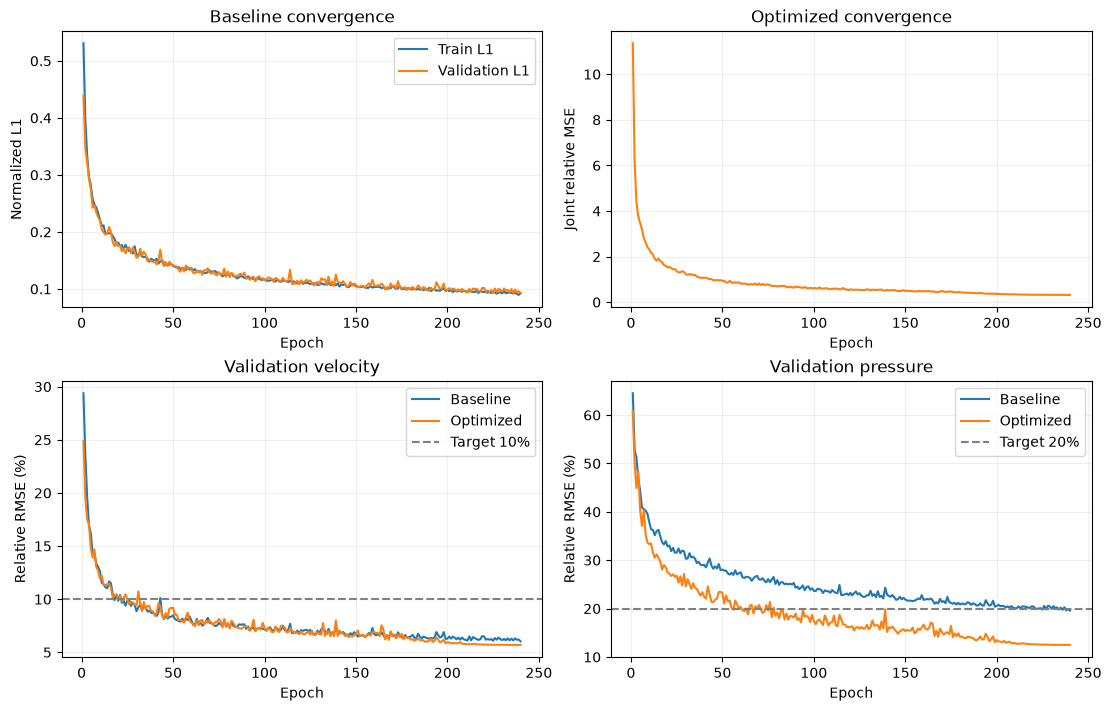

In [16]:
# 실제 학습 손실과 공통 검증 지표
curves = {method: pd.DataFrame(histories[method]) for method in METHODS}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
axes[0, 0].plot(curves['baseline']['epoch'], curves['baseline']['train_loss'], label='Train L1')
axes[0, 0].plot(curves['baseline']['epoch'], curves['baseline']['val_loss'], label='Validation L1')
axes[0, 0].set(title='Baseline convergence', ylabel='Normalized L1')
axes[0, 1].plot(curves['optimized']['epoch'], curves['optimized']['train_loss'], color='tab:orange')
axes[0, 1].set(title='Optimized convergence', ylabel='Joint relative MSE')
for ax, key, label, limit in zip(axes[1], ['velocity_vector_relative_rmse', 'pressure_relative_rmse'],
                                ['Validation velocity', 'Validation pressure'], [10, 20]):
    for method in METHODS:
        ax.plot(curves[method]['epoch'], 100 * curves[method][key], label=method.capitalize())
    ax.axhline(limit, color='gray', linestyle='--', label=f'Target {limit}%')
    ax.set(title=label, ylabel='Relative RMSE (%)')
    ax.legend()
for ax in axes.flat:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=.2)
axes[0, 0].legend()
plt.show()


In [17]:
# 검증으로 선택한 각 모델의 실측값
validation_rows = []
for method in METHODS:
    record = best_records[method]
    validation_rows.append({'모델': method, '선택 epoch': record['epoch'],
        '속도 상대 RMSE [%]': 100 * record['velocity_vector_relative_rmse'],
        '압력 상대 RMSE [%]': 100 * record['pressure_relative_rmse'],
        '최종 선택': method == selected_method})
display(pd.DataFrame(validation_rows).set_index('모델').round(3))
print('최종 가중치:', WEIGHT, '/ 선택 모델:', selected_method)


,선택 epoch,속도 상대 RMSE [%],압력 상대 RMSE [%],최종 선택
모델,,,,
baseline,240,6.036,19.587,False
optimized,233,5.700,12.499,True


최종 가중치: ../weights/best.pt / 선택 모델: optimized


In [18]:
# 이번 학습에서 저장한 최종 가중치 복원
selected_model, final_checkpoint = load_prediction_model(WEIGHT, DEVICE)
if not final_checkpoint['training_complete']:
    raise ValueError('Final checkpoint training is incomplete')
if final_checkpoint['manifest_sha256'] != manifest_sha256:
    raise ValueError('Final checkpoint dataset differs')
print('저장된 선택 epoch:', final_checkpoint['epoch'])


저장된 선택 epoch: 233


## 5) 모델 테스트
- 모델 선택이 끝난 뒤 학습에서 제외한 테스트 36건으로 실제 예측
- 첫 테스트 사례를 CFD, 기준 모델, 개선 모델의 3D Volume과 Stream Line으로 비교
- 같은 좌표, 카메라, 유속 범위와 유선 시작점을 사용하며 최종 선택 모델을 표시


In [19]:
# 두 모델의 테스트 예측과 유효 유체 영역 오차
representative_file = test_entries[0]['file']
representative_predictions, test_results = {}, {}
for method in METHODS:
    model = selected_model if method == selected_method else build_model(MODEL_CONFIG).to(DEVICE)
    if method != selected_method:
        model.load_state_dict(best_states[method])
    model.eval()
    rows, pooled = [], MetricAccumulator()
    with torch.inference_mode():
        for index, entry in enumerate(test_entries):
            case = load_case(DATA / entry['file'])
            target = case.pop('target')
            encoded = encode_case(case, normalization)
            spatial = torch.from_numpy(encoded['spatial']).unsqueeze(0).to(DEVICE)
            conditions = torch.from_numpy(encoded['conditions']).unsqueeze(0).to(DEVICE)
            normalized = model(spatial, conditions)[0].float().cpu().numpy()
            physical = restore_physical_prediction(normalized, case, normalization)
            valid = (case['fluid_mask'] & case['valid_mask'])[0]
            rows.append({'file': entry['file'], **compute_metrics(physical, target, valid)})
            pooled.update(physical, target, valid)
            if index == 0:
                representative_case, representative_target = case, target
                representative_predictions[method] = physical
    test_results[method] = dict(per_case=rows, pooled=pooled.compute())


In [20]:
# 전체 테스트의 사례 평균과 전체 셀 집계
summary = []
for method, result in test_results.items():
    for label, metrics in [('사례 평균', pd.DataFrame(result['per_case'])[
            ['velocity_vector_relative_rmse', 'pressure_relative_rmse']].mean().to_dict()),
            ('전체 셀', result['pooled'])]:
        summary.append({'모델': method, '집계': label,
            '속도 상대 RMSE [%]': 100 * metrics['velocity_vector_relative_rmse'],
            '압력 상대 RMSE [%]': 100 * metrics['pressure_relative_rmse']})
display(pd.DataFrame(summary).set_index(['모델', '집계']).round(3))
print('3D 비교 사례:', representative_file)
final_payload['test_results'] = test_results
atomic_torch_save(WEIGHT, final_payload)


속도 상대 RMSE [%]  압력 상대 RMSE [%]
모델        집계                                   
baseline  사례 평균           6.135          19.425
          전체 셀            6.156          19.288
optimized 사례 평균           5.782          12.561
          전체 셀            5.793          12.517

3D 비교 사례: wind_042_speed_02.npz


In [21]:
# 물리 좌표의 셀 격자와 장애물
pv.set_plot_theme('document')
comparison_valid = (representative_case['fluid_mask'] & representative_case['valid_mask'])[0]
comparison_origin = representative_case['origin']
comparison_spacing = representative_case['spacing']
comparison_nz, comparison_ny, comparison_nx = comparison_valid.shape
comparison_grid = pv.ImageData(dimensions=(comparison_nx + 1, comparison_ny + 1, comparison_nz + 1),
    origin=comparison_origin, spacing=comparison_spacing)
comparison_grid.cell_data['valid'] = comparison_valid.ravel().astype('uint8')
comparison_grid.cell_data['solid'] = (~representative_case['fluid_mask'][0]).ravel().astype('uint8')
comparison_buildings = comparison_grid.threshold(.5, scalars='solid', preference='cell').extract_surface()


In [22]:
# CFD와 두 학습 모델의 공통 유속 범위
comparison_titles = ['CFD', 'Baseline', 'Optimized']
comparison_methods = ['CFD', 'baseline', 'optimized']
comparison_fields = [representative_target, representative_predictions['baseline'],
                     representative_predictions['optimized']]
comparison_speed_max = 0.0
for index, field in enumerate(comparison_fields):
    if not np.isfinite(field[:, comparison_valid]).all():
        raise ValueError(f'Non-finite visualization field: {comparison_titles[index]}')
    speed = np.linalg.norm(field[:3], axis=0)
    comparison_speed_max = max(comparison_speed_max, float(speed[comparison_valid].max()))
    comparison_grid.cell_data[f'speed_{index}'] = np.where(comparison_valid, speed, 0).ravel()
    comparison_grid.cell_data[f'velocity_{index}'] = field[:3].reshape(3, -1).T
comparison_speed_max = max(comparison_speed_max, 1e-12)


In [23]:
# 장애물과 실제 3D 유속 체적 비교
volume_plotter = pv.Plotter(shape=(1, 3), off_screen=True, window_size=(1800, 700))
for index, title in enumerate(comparison_titles):
    volume_plotter.subplot(0, index)
    volume_plotter.add_volume(comparison_grid, scalars=f'speed_{index}', cmap='viridis',
        clim=(0, comparison_speed_max), mapper='fixed_point', opacity=[0, .01, .03, .06, .1],
        opacity_unit_distance=3, scalar_bar_args=dict(title='Speed (m/s)', use_opacity=False,
            vertical=False, width=.6, height=.05, position_x=.2, position_y=.03,
            title_font_size=10, label_font_size=9, n_labels=3))
    if comparison_buildings.n_cells:
        volume_plotter.add_mesh(comparison_buildings, color='lightgray')
    volume_plotter.add_mesh(comparison_grid.outline(), color='gray', line_width=1)
    volume_plotter.add_text(title + (' (selected)' if comparison_methods[index] == selected_method else ''),
                            font_size=11)
    volume_plotter.show_bounds(bounds=comparison_grid.bounds, xtitle='x (m)', ytitle='y (m)',
        ztitle='z (m)', font_size=8, use_3d_text=False, n_xlabels=3, n_ylabels=3, n_zlabels=3)


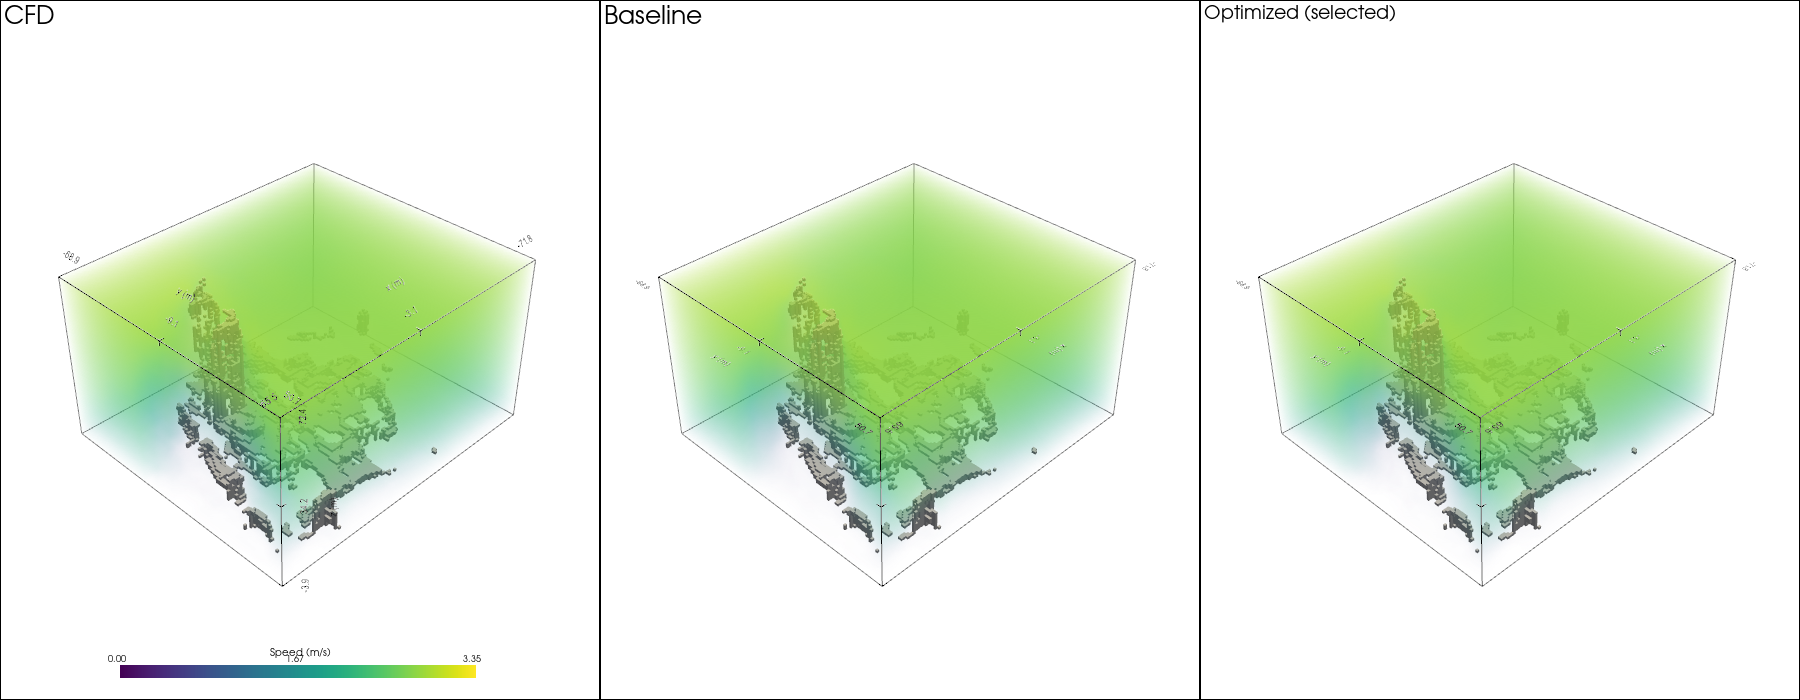

In [24]:
# 공통 시점의 체적 렌더링 결과
volume_plotter.subplot(0, 0)
volume_plotter.view_isometric()
volume_plotter.reset_camera(bounds=comparison_grid.bounds)
volume_plotter.camera.zoom(.85)
volume_plotter.link_views()
volume_plotter.show(jupyter_backend='static')
volume_plotter.close()


In [25]:
# 유효 유체 영역의 동일한 유선 시작점
comparison_flow = comparison_grid.threshold(.5, scalars='valid', preference='cell')
comparison_points = comparison_flow.cell_centers().points
comparison_ground = representative_case['metadata']['ground_z']
comparison_points = comparison_points[(comparison_points[:, 2] > comparison_ground + 3)
                                    & (comparison_points[:, 2] < comparison_ground + 30)]
if not len(comparison_points):
    raise ValueError('No valid streamline seeds between 3 and 30 m above ground')
comparison_seeds = pv.PolyData(comparison_points[
    np.linspace(0, len(comparison_points) - 1, min(72, len(comparison_points)), dtype=int)])
comparison_flow = comparison_flow.cell_data_to_point_data()


In [26]:
# 물리 속도 벡터를 적분한 실제 3D 유선
comparison_traces = []
for index, title in enumerate(comparison_titles):
    lines = comparison_flow.streamlines_from_source(comparison_seeds, vectors=f'velocity_{index}',
        integration_direction='both', interpolator_type='cell', initial_step_length=.5,
        max_step_length=.5, max_length=2 * comparison_flow.length, max_steps=2000,
        terminal_speed=1e-4, compute_vorticity=False)
    if not lines.n_cells:
        raise ValueError(f'No streamlines generated: {title}')
    lines['Speed'] = np.linalg.norm(lines[f'velocity_{index}'], axis=1)
    comparison_traces.append(lines)


In [27]:
# 같은 시작점과 유속 색상 범위의 3D 유선 비교
stream_plotter = pv.Plotter(shape=(1, 3), off_screen=True, window_size=(1800, 700))
for index, title in enumerate(comparison_titles):
    stream_plotter.subplot(0, index)
    actor = stream_plotter.add_mesh(comparison_traces[index], scalars='Speed', cmap='viridis',
        clim=(0, comparison_speed_max), line_width=3, render_lines_as_tubes=True, lighting=False,
        scalar_bar_args=dict(title='Speed (m/s)', vertical=False, width=.6, height=.05,
            position_x=.2, position_y=.03, title_font_size=10, label_font_size=9, n_labels=3))
    actor.UseBoundsOff()
    if comparison_buildings.n_cells:
        stream_plotter.add_mesh(comparison_buildings, color='lightgray')
    stream_plotter.add_mesh(comparison_grid.outline(), color='gray', line_width=1)
    stream_plotter.add_text(title + (' (selected)' if comparison_methods[index] == selected_method else ''),
                            font_size=11)
    stream_plotter.show_bounds(bounds=comparison_grid.bounds, xtitle='x (m)', ytitle='y (m)',
        ztitle='z (m)', font_size=8, use_3d_text=False, n_xlabels=3, n_ylabels=3, n_zlabels=3)


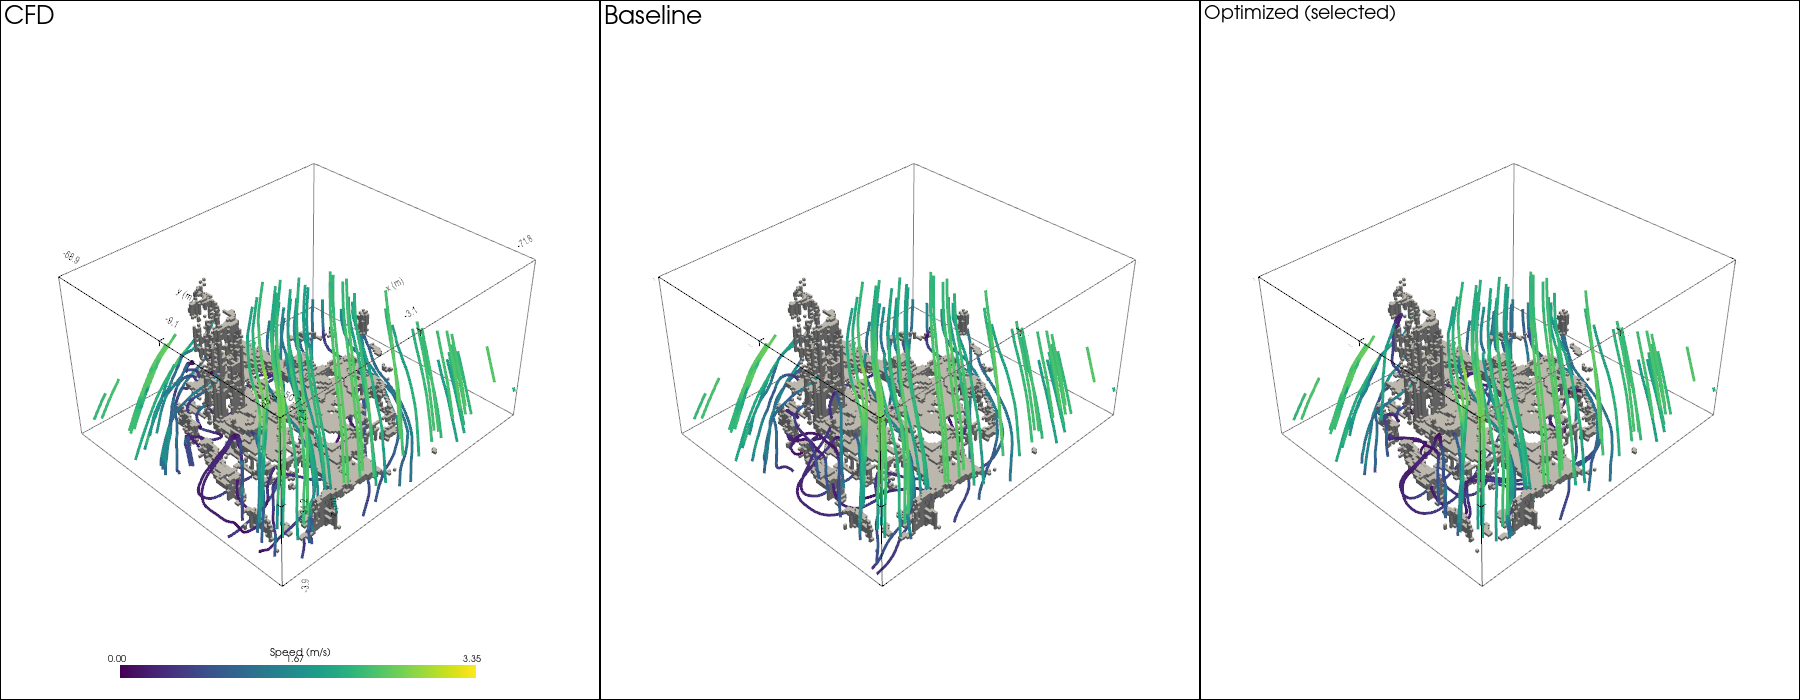

In [28]:
# 공통 시점의 유선 렌더링 결과
stream_plotter.subplot(0, 0)
stream_plotter.view_isometric()
stream_plotter.reset_camera(bounds=comparison_grid.bounds)
stream_plotter.camera.zoom(.85)
stream_plotter.link_views()
stream_plotter.show(jupyter_backend='static')
stream_plotter.close()
